# Prueba técnica – Científico/a de Datos (INE)
**Guillermo S. Fuentes-Jaque**

| Pregunta | Sección |
|---|---|
| 1. Clasificando texto | TF‑IDF (palabras + caracteres) + LinearSVC, análisis de errores y plan de mejora |
| 2. Modelo en producción | Intervalos de confianza, simulación del ruido con n=100, hipótesis y estrategia |
| 3. Procesando texto | Resúmenes de máximo 50 palabras con OpenRouter y reporte automático (`reporte_resumenes.md`) |
| 4. Cuéntanos sobre un proyecto | Respuesta que se exporta automáticamente a `pregunta4_proyecto.md` |

**Cómo ejecutarlo:** de arriba hacia abajo, con *Ejecutar todo*. Las preguntas dependen en orden: la 2 reutiliza las predicciones de la 1.

- **Base de datos:** es compartida y a veces rechaza conexiones. Los lectores reintentan con espera exponencial y guardan una copia local en `data/` que se usa como respaldo. Esa carpeta no se incluye en el repositorio.
- **API key de OpenRouter:** se lee automáticamente desde **el archivo enlazado en el enunciado**. Si cambia, el notebook toma la nueva. **El archivo `.env` no se incluye en el repositorio**; solo se usa como respaldo local.


## Instalación

In [1]:
# En Colab ya vienen pandas, numpy, scikit-learn, scipy, matplotlib y requests
%pip install -q mysql-connector-python python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: D:\proyectos IA\ine-prueba-tecnica\.venv\Scripts\python.exe -m pip install --upgrade pip


---

# Pregunta 1 – Clasificando texto

**Objetivo:** predecir `cod_final` (código de actividad económica, 2 dígitos) a partir de tres campos de texto libre: `actividad`, `oficio` y `tareas`.

**Enfoque (sin optimizar, por instrucción de la prueba):** TF‑IDF de palabras + n‑gramas de caracteres sobre los tres campos, y un clasificador lineal (`LinearSVC`).
Es un baseline fuerte, rápido de entrenar y fácil de interpretar para texto corto con muchas clases.

In [2]:
import time
import unicodedata

import matplotlib.pyplot as plt
import mysql.connector
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, make_union
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

pd.set_option("display.max_colwidth", 80)
SEED = 42

## 1) Descarga de la tabla `train`

La base es un MySQL gratuito y **compartido** (freedb), con dos limitaciones que encontré al explorarla:
- **Límite de conexiones simultáneas por usuario:** otros postulantes usan las mismas credenciales, así que la conexión reintenta con espera.
- **Tiempo máximo por consulta:** un `SELECT *` de las ~35 mil filas de `train` se corta, así que leo por bloques de 2000 filas paginando por `id`, y reintento cualquier bloque que falle.
- **Respaldo:** cada lectura exitosa se guarda en `data/<tabla>.csv`. Si la base no responde, el notebook usa esa copia. En Colab basta con subir los CSV a una carpeta `data/`.

In [3]:
# Solo en Colab: montar los CSV de respaldo si la base no responde (opcional)
# from google.colab import files; import os; os.makedirs("data", exist_ok=True)
# for nombre, contenido in files.upload().items(): open(f"data/{nombre}", "wb").write(contenido)

Lectura de `train`:

In [4]:
DB = dict(host="sql.freedb.tech", port=3306, user="u_y8tlWZ",
          password="wSkxw3xbhsQg", database="freedb_N4nnid0a")

import os

def conectar(reintentos=12):
    for i in range(reintentos):
        try:
            return mysql.connector.connect(**DB, connection_timeout=20)
        except mysql.connector.Error as e:
            espera = min(5 * 1.5 ** i, 30)  # espera exponencial, tope 30s
            print(f"intento {i+1}: {e.msg[:60]} -> reintento en {espera:.0f}s")
            time.sleep(espera)
    raise ConnectionError("No fue posible conectarse a la base")

def leer_tabla(tabla):
    """Intenta leer desde MySQL y guarda una copia en data/<tabla>.csv.
    Si la base no responde (está compartida y suele saturarse), usa esa copia como respaldo."""
    ruta = f"data/{tabla}.csv"
    try:
        df = leer_tabla_mysql(tabla)
        os.makedirs("data", exist_ok=True)
        df.to_csv(ruta, index=False)
        print(f"{tabla}: {len(df)} filas leídas desde MySQL (copia en {ruta})")
    except (ConnectionError, RuntimeError) as e:
        print(f"{tabla}: MySQL no disponible ({e}). Usando respaldo {ruta}")
        df = pd.read_csv(ruta, dtype={"cod_final": str})
    df["cod_final"] = df["cod_final"].astype(str).str.zfill(2) if "cod_final" in df else None
    return df

def leer_tabla_mysql(tabla, bloque=2000, reintentos=5):
    """Lee la tabla por bloques usando paginación por id (WHERE id > último), más barata que OFFSET.
    Si un bloque falla (timeout o conexión caída), reconecta y reintenta solo ese bloque."""
    cnx = conectar()
    filas, ultimo_id, cols = [], -1, None
    try:
        while True:
            for intento in range(reintentos):
                try:
                    cur = cnx.cursor()
                    cur.execute(f"SELECT * FROM {tabla} WHERE id > %s ORDER BY id LIMIT %s", (ultimo_id, bloque))
                    parte, cols = cur.fetchall(), [d[0] for d in cur.description]
                    cur.close()
                    break
                except mysql.connector.Error as e:
                    print(f"bloque desde id {ultimo_id}: {e.msg[:60]} -> reintento")
                    try: cnx.close()
                    except Exception: pass
                    time.sleep(3)
                    cnx = conectar()
            else:
                raise RuntimeError(f"No se pudo leer el bloque desde id {ultimo_id}")
            filas.extend(parte)
            if len(parte) < bloque:
                break
            ultimo_id = parte[-1][cols.index("id")]
        return pd.DataFrame(filas, columns=cols)
    finally:
        cnx.close()

train = leer_tabla("train")
print(train.shape)
train.head()

train: 35340 filas leídas desde MySQL (copia en data/train.csv)
(35340, 5)


,id,actividad,oficio,tareas,cod_final
0,0,producción uva exportación,temporera agrícola,mantenimiento de parronales,01
1,1,corporación municipal,profesor mecánico industrial,"preparar clases, enseñar",84
2,4,contratista de rrhh para obras de construcción,trabajador de construcción,veredas,41
3,5,municipalidad de puerto natales,técnico paramedico,"toma de signos vitales, entrega de horas a pacientes, tratamientos inyectabl...",84
4,7,guardias seguridad y proteccion,administrador de contrato,administrar dirigir contratar personal,80


## Exploración rápida

In [5]:
vacios = train[["actividad", "oficio", "tareas"]].apply(lambda s: s.fillna("").astype(str).str.strip().isin(["", "None", "nan"]))
print("Campos vacíos o nulos por columna:\n", vacios.sum(), sep="")
print("\nClases distintas:", train.cod_final.nunique())

largo = train[["actividad", "oficio", "tareas"]].apply(lambda s: s.fillna("").str.split().str.len())
print("\nLargo (palabras) por campo:")
print(largo.describe().loc[["mean", "50%", "max"]].round(1))

dup = train.duplicated(["actividad", "oficio", "tareas"]).sum()
conflicto = (train.groupby(["actividad", "oficio", "tareas"]).cod_final.nunique() > 1).sum()
print(f"\nTextos duplicados: {dup} | textos idénticos con códigos distintos: {conflicto}")

Campos vacíos o nulos por columna:
actividad      0
oficio       453
tareas       455
dtype: int64

Clases distintas: 79



Largo (palabras) por campo:
      actividad  oficio  tareas
mean        4.3     2.6     6.0
50%         4.0     3.0     6.0
max        23.0    15.0    30.0



Textos duplicados: 426 | textos idénticos con códigos distintos: 9


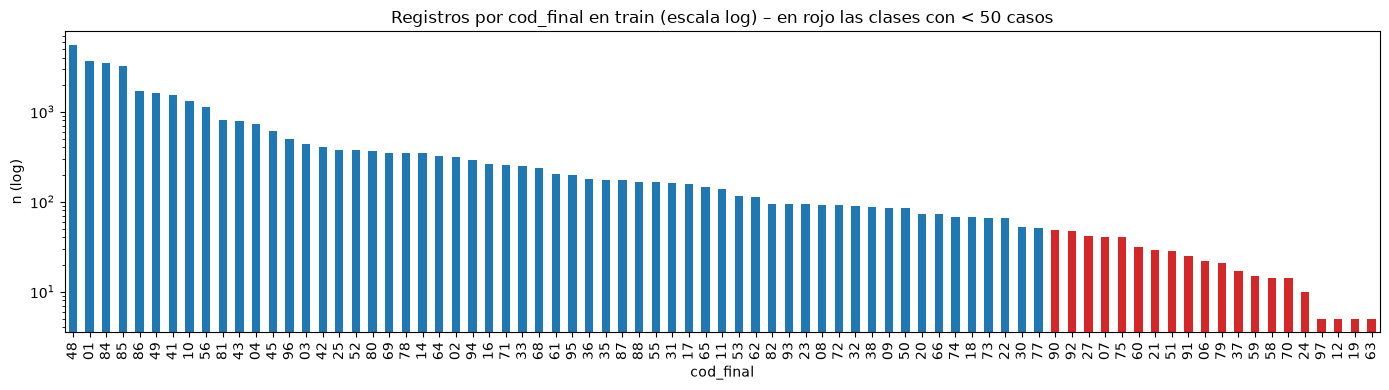

Top 5 clases = 49.5% de los datos
Clases con < 50 casos: 20 | con < 10 casos: 4


In [6]:
frec = train.cod_final.value_counts()
fig, ax = plt.subplots(figsize=(14, 4))
frec.plot.bar(ax=ax, color=np.where(frec < 50, "tab:red", "tab:blue"), logy=True)
ax.set_title("Registros por cod_final en train (escala log) – en rojo las clases con < 50 casos")
ax.set_xlabel("cod_final"); ax.set_ylabel("n (log)")
plt.tight_layout(); plt.show()

print(f"Top 5 clases = {frec.head(5).sum() / len(train):.1%} de los datos")
print(f"Clases con < 50 casos: {(frec < 50).sum()} | con < 10 casos: {(frec < 10).sum()}")

**Lectura de la exploración:**
- **Textos muy cortos:** la mediana es de 3 a 6 palabras por campo. Hay poco contexto, así que cada palabra pesa mucho.
- **Ruido de digitación:** hay faltas de ortografía y abreviaturas, como *"cultivo dd frambuesas"* o *"mantencion electrica"*. Por eso conviene sumar n‑gramas de **caracteres**, que son robustos a errores de tipeo, y no solo palabras.
- **Desbalance fuerte:** 79 clases, la mitad de los datos en 5 clases y 20 clases con menos de 50 casos. La accuracy va a sobreestimar la calidad del modelo, así que miro también el **F1 macro**.
- **Ruido en la etiqueta:** hay textos idénticos con códigos distintos. Eso pone un techo al desempeño alcanzable.

## 2) Procesamiento y entrenamiento

**Decisiones de procesamiento:**
1. Minúsculas y sin tildes, para unificar "agrícola" y "agricola".
2. Nulos convertidos en texto vacío. Son pocos, ver el conteo de campos vacíos en la exploración.
3. Concateno los tres campos **anteponiendo el nombre del campo** a cada palabra (`act_`, `ofi_`, `tar_`). Así el modelo distingue "construcción" como actividad de la empresa de "construcción" como tarea. La actividad de la empresa es la señal más directa del código, porque `cod_final` clasifica la actividad económica.

**Representación:**
- TF‑IDF de palabras (1‑2 gramas).
- TF‑IDF de caracteres (2‑5 gramas, `char_wb`) sobre el texto sin prefijos, para capturar raíces y errores de tipeo.

**Modelo:** `LinearSVC`, por estas razones:
- Es el estándar para texto disperso de alta dimensión y entrena en segundos con decenas de miles de filas.
- Maneja bien muchas clases (uno‑contra‑resto).
- No uso `class_weight="balanced"` de partida. Es una decisión a evaluar, no a optimizar ahora (ver plan de mejora).

Separo un 10% de `train` como validación, solo para tener una referencia antes de mirar `test`.

In [7]:
def normalizar(s):
    s = s.fillna("").astype(str).str.lower()
    return s.map(lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode())

def con_prefijo(s, pref):
    return s.str.split().map(lambda ws: " ".join(pref + w for w in ws))

def preparar(df):
    a, o, t = (normalizar(df[c]) for c in ["actividad", "oficio", "tareas"])
    return pd.DataFrame({
        "palabras": con_prefijo(a, "act_") + " " + con_prefijo(o, "ofi_") + " " + con_prefijo(t, "tar_"),
        "plano": a + " | " + o + " | " + t,
    })

from sklearn.compose import ColumnTransformer

vectorizador = ColumnTransformer([
    ("pal", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "palabras"),
    ("car", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "plano"),
])
modelo = make_pipeline(vectorizador, LinearSVC(C=0.5, random_state=SEED))

X, y = preparar(train), train.cod_final.astype(str)
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.1, stratify=y, random_state=SEED)

t0 = time.time()
modelo.fit(X_tr, y_tr)
pred_val = modelo.predict(X_val)
print(f"Entrenado en {time.time()-t0:.0f}s")
print(f"Validación -> accuracy: {accuracy_score(y_val, pred_val):.3f} | F1 macro: {f1_score(y_val, pred_val, average='macro'):.3f}")

Entrenado en 46s
Validación -> accuracy: 0.911 | F1 macro: 0.744


Con la referencia de validación, reentreno con **todo** `train` para predecir `test`.

In [8]:
modelo.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearsvc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](79,)","['01','02','03',...,'95','96','97']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['palabras','plano']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pal', ...), ('car', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining co

## 3) Descarga de la tabla `test`

In [9]:
test = leer_tabla("test")
print(test.shape)
test.head()

test: 3927 filas leídas desde MySQL (copia en data/test.csv)
(3927, 5)


,id,actividad,oficio,tareas,cod_final
0,2,"mantención, reparación y construcción de redes de alcantarillado",ayudante en obras civiles,"traslada herramientas, hace excavación",42
1,3,servicios agricolas,encargada de certificación en campo,"revisar cuadernos, revisar labores de riego, organizar distribución de habit...",01
2,13,servicio de seguridad,guardia de seguridad,vigilar cámaras de seguridad en tribunales,80
3,21,suministrador de trabajadores para servicio de mecánica industrial,supervisor mecánico,supervisar mantenimiento mecánico y cambios de piezas,33
4,27,municipalidad,profesor de educación física,"programar, organizar y evaluar tareas",84


## 4) Predicciones sobre `test`

In [10]:
X_te, y_te = preparar(test), test.cod_final.astype(str)
test["pred"] = modelo.predict(X_te)
# margen entre la 1a y 2a clase de la SVM: proxy de confianza para el análisis de errores
dec = modelo.decision_function(X_te)
orden = np.sort(dec, axis=1)
test["margen"] = orden[:, -1] - orden[:, -2]
# se guardan para reutilizarlas en la Pregunta 2 (simular muestras mensuales de 100 casos)
test[["id", "cod_final", "pred", "margen"]].to_csv("data/test_predicciones.csv", index=False)

acc = accuracy_score(y_te, test.pred)
f1m = f1_score(y_te, test.pred, average="macro")
f1w = f1_score(y_te, test.pred, average="weighted")
print(f"TEST -> accuracy: {acc:.3f} | F1 macro: {f1m:.3f} | F1 ponderado: {f1w:.3f}")
test[["actividad", "oficio", "tareas", "cod_final", "pred"]].head(10)

TEST -> accuracy: 0.917 | F1 macro: 0.785 | F1 ponderado: 0.915


,actividad,oficio,tareas,cod_final,pred
0,"mantención, reparación y construcción de redes de alcantarillado",ayudante en obras civiles,"traslada herramientas, hace excavación",42,42
1,servicios agricolas,encargada de certificación en campo,"revisar cuadernos, revisar labores de riego, organizar distribución de habit...",01,01
2,servicio de seguridad,guardia de seguridad,vigilar cámaras de seguridad en tribunales,80,80
3,suministrador de trabajadores para servicio de mecánica industrial,supervisor mecánico,supervisar mantenimiento mecánico y cambios de piezas,33,78
4,municipalidad,profesor de educación física,"programar, organizar y evaluar tareas",84,84
5,jardineria,jardinero,realiza manutención de jardines,81,81
6,contratación de personal,cajera bancaria,"atención de público, recepción de dinero, cuadratura",78,78
7,suministradora de trabajadores,recepcionista,"recibe pacientes, orienta, entrega protocolo",78,78
8,administración de establecimientos educacionales,profesora de artes visuales,impartir clases de artes visuales vía remota a alumnos de educación basica,84,85
9,construcción de veredas,maestro de la construccion,hacer veredas,42,42


## 5) Análisis de resultados

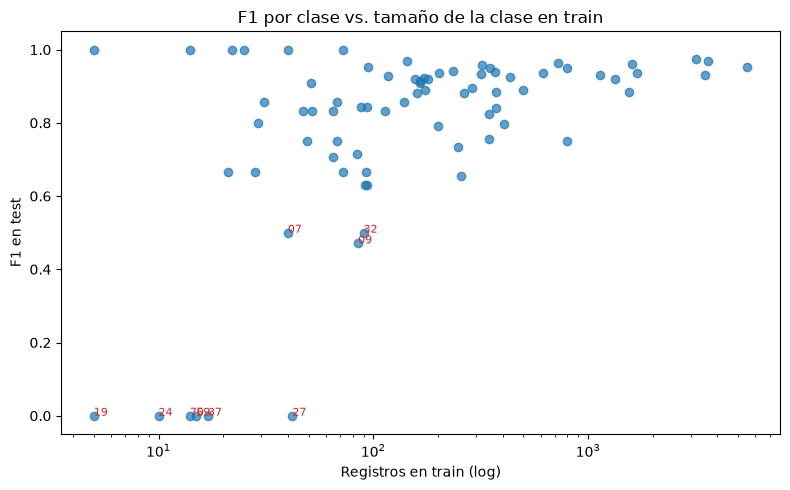

Peores 12 clases (F1 en test):


,precision,recall,f1-score,support,n_train
19,0.00,0.00,0.00,1,5
37,0.00,0.00,0.00,2,17
24,0.00,0.00,0.00,1,10
27,0.00,0.00,0.00,5,42
70,0.00,0.00,0.00,1,14
59,0.00,0.00,0.00,2,15
09,0.57,0.40,0.47,10,85
32,0.67,0.40,0.50,10,90
07,0.67,0.40,0.50,5,40
72,0.67,0.60,0.63,10,91


In [11]:
rep = pd.DataFrame(classification_report(y_te, test.pred, output_dict=True, zero_division=0)).T
rep = rep.drop(["accuracy", "macro avg", "weighted avg"]).astype({"support": int})
rep["n_train"] = rep.index.map(frec).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(rep.n_train, rep["f1-score"], alpha=.7)
for c, r in rep.iterrows():
    if r["f1-score"] < 0.6:
        ax.annotate(c, (r.n_train, r["f1-score"]), fontsize=8, color="tab:red")
ax.set_xscale("log"); ax.set_xlabel("Registros en train (log)"); ax.set_ylabel("F1 en test")
ax.set_title("F1 por clase vs. tamaño de la clase en train")
plt.tight_layout(); plt.show()

print("Peores 12 clases (F1 en test):")
rep.sort_values("f1-score").head(12).round(2)

In [12]:
# Pares de clases que más se confunden
err = test[test.cod_final != test.pred]
pares = err.groupby(["cod_final", "pred"]).size().sort_values(ascending=False).rename("n").reset_index()
print(f"Errores: {len(err)} de {len(test)}")
pares.head(10)

Errores: 324 de 3927


,cod_final,pred,n
0,43,41,15
1,41,43,9
2,84,85,8
3,86,84,7
4,84,86,6
5,85,84,6
6,42,41,5
7,48,01,5
8,10,48,5
9,56,48,5


In [13]:
# Ejemplos concretos de errores (para entender si es el modelo o la etiqueta)
err.sort_values("margen", ascending=False)[["actividad", "oficio", "tareas", "cod_final", "pred", "margen"]].head(10)

,actividad,oficio,tareas,cod_final,pred,margen
244,fundación de educación de colegio de enseñanza básica y media.,auxiliar de servicio de aseo de un colegio.,"hacer el aseo, barrer, botar la basura etc.",94,85,2.880017
603,servicio de alimentación a colegios,manipuladora de alimentos,preparación alimentación escolar,85,56,2.835507
3910,VENTA DE AROMATERAPIA,,,86,48,2.743004
1648,departamento de salud municipal,enfermera,tomas de muestras covid domiciliarias,86,84,2.624569
3620,reparacion de viviendas,maestro de la construcción,colocar cerámica,43,41,2.527840
3030,"servicios de pintura, construccion y remodelacion de viviendas",maestro en construcciónes generales,"pintura de viviendas, construcción, cerámica, remodelaciones",43,41,2.322127
2303,corporacion municipal,medico pediatra,atencion de pacientes,86,84,2.126598
3295,venta de rop de mujer por mayor,comerciante de ropa,elaboracion y venta de ropa,14,48,2.090710
3188,construccion de radier,maestro albañil,"preparar mezcla, rellenar, hacer radier",42,41,2.071505
988,municipalidad de los vilos,auxiliar de apoyo,"realizar aseo, entrega medicamentos, ir a dejar medica,estos a viviendas de ...",86,84,2.051159


In [14]:
# ¿Sirve el margen como señal de confianza? Accuracy por quintil de margen
test["quintil_margen"] = pd.qcut(test.margen, 5, labels=["Q1 (baja)", "Q2", "Q3", "Q4", "Q5 (alta)"])
test.groupby("quintil_margen", observed=True).apply(lambda d: pd.Series({
    "n": len(d), "accuracy": (d.cod_final == d.pred).mean()})).round(3)

,n,accuracy
quintil_margen,,
Q1 (baja),786.0,0.672
Q2,785.0,0.943
Q3,785.0,0.986
Q4,785.0,0.994
Q5 (alta),786.0,0.994


### Fortalezas y espacios de mejora

**Resultado global en test (3.927 casos):** accuracy **0,917**, F1 macro **0,785**, F1 ponderado **0,915**. Son 324 errores. En validación (10% de train) el resultado fue similar (0,911 / 0,744): no hay señales de sobreajuste a una partición.

**Fortalezas**
- **Muy buen desempeño en las clases que concentran el volumen.**

  | Código | Actividad | Accuracy |
  |---|---|---|
  | 48 | comercio | 97,4% |
  | 85 | enseñanza | 97,7% |
  | 01 | agricultura | 96,5% |
  | 84 | administración pública | 93,6% |
  | 86 | salud | 93,6% |

  Como esas clases son la mitad de los datos, el modelo ya resolvería bien la mayor parte de la carga de codificación.
- **Simple, rápido e interpretable.**
  - Entrena en alrededor de un minuto, sin GPU.
  - Cada decisión se puede explicar con los pesos de las palabras.
  - Los n‑gramas de caracteres toleran errores de digitación ("rop de mujer", "construcciónes").
- **El margen de decisión es una muy buena señal de confianza.**

  | Quintil de margen | Accuracy |
  |---|---|
  | Q1 (el 20% menos seguro) | 67% |
  | Q2 | 94% |
  | Q3 a Q5 | 98,6% a 99,4% |

  Esto permite un esquema de **codificación asistida**: si el 30% de menor confianza se deriva a codificadores humanos, el 70% automático tiene **98,8% de accuracy** y la revisión humana concentra el **90% de los errores**. Para una oficina de estadística, donde importa la calidad del dato publicado, esto vale más que subir un punto de accuracy global.

**Espacios de mejora**
- **Clases pequeñas.** El F1 macro (0,785) está 13 puntos bajo la accuracy. Hay **6 clases con F1 = 0** (19, 24, 27, 37, 59, 70), todas con 45 ejemplos o menos en train y entre 1 y 5 casos en test: el modelo casi nunca las predice. Con tan pocos casos de test, además, su F1 es muy inestable.
- **Confusiones entre clases vecinas.** Los errores no son aleatorios, se concentran en pares con frontera difusa:
  - **43 ↔ 41** (24 errores): actividades especializadas de construcción frente a construcción de edificios. "Maestro de la construcción que coloca cerámica" puede ser cualquiera de las dos. 43 es la clase grande con menor accuracy (77,5%).
  - **84 ↔ 85 ↔ 86** (al menos 27 errores entre los pares más frecuentes): administración pública, enseñanza y salud. El caso típico es el **trabajador municipal**: un médico o enfermera de un departamento de salud municipal se codifica como salud (86), pero el modelo se deja llevar por "municipal" y predice 84. Aquí la regla de codificación prioriza **la función del establecimiento** sobre quién es el empleador, y el modelo no la conoce.
- **Ruido o ambigüedad en la etiqueta.** Varios errores con **margen alto**, donde el modelo estaba muy seguro, son discutibles:
  - "fundación de educación … auxiliar de aseo de un colegio" está etiquetado como 94 (asociaciones) y el modelo predice 85;
  - "venta de aromaterapia" está etiquetado como salud (86).

  En train también hay 9 textos idénticos con códigos distintos. Esto pone un techo al desempeño y hace que parte de los "errores" no sean del modelo.
- **Sin semántica.** La bolsa de palabras no sabe que "radier" y "veredas" son trabajos de construcción si no los vio, ni generaliza a vocabulario nuevo. Eso conecta directamente con el riesgo de drift de la Pregunta 2.

## 6) Plan de mejora (sin ejecutar)

1. **Validación más sólida:** validación cruzada estratificada y F1 macro como métrica principal, para que las decisiones no dependan de una sola partición.
2. **Desbalance:**
   - probar `class_weight="balanced"` o pesos intermedios;
   - agrupar las clases ultra‑raras (menos de 10 casos) para entrenar, o resolverlas con reglas;
   - aumentar datos de las clases chicas.
3. **Calidad de etiquetas:** revisar los textos duplicados con códigos en conflicto y los errores con margen alto. Si son errores de etiqueta, corregirlos mejora el entrenamiento y la evaluación.
4. **Representación:**
   - ajustar n‑gramas y `min_df` y pesar distinto cada campo, con una búsqueda corta de hiperparámetros;
   - probar corrección ortográfica o un diccionario de abreviaturas.
5. **Modelos con semántica:**
   - embeddings de oraciones en español (por ejemplo sentence‑transformers multilingües) más un clasificador lineal;
   - fine‑tuning de un BERT en español (BETO o RoBERTa‑BNE);
   - mantener el TF‑IDF como baseline y comparar con F1 macro.
6. **Jerarquía de la clasificación:** el código de 2 dígitos se agrupa en secciones (letras). Un modelo jerárquico o un análisis de errores por sección reduce las confusiones lejanas.
7. **Uso en producción con umbral:** aprovechar el margen o probabilidades calibradas (`CalibratedClassifierCV`) para codificar automáticamente solo los casos de alta confianza y enviar el resto a codificadores humanos. Según este test, derivando el 30% menos seguro se automatiza el 70% con ~99% de accuracy. El umbral se elige según la capacidad del equipo de codificación y la calidad exigida.
8. **Incorporar reglas de codificación conocidas:** por ejemplo, salud o educación municipal se codifica por la función del establecimiento. Se puede hacer como variables adicionales, como reglas de post‑proceso o como ejemplos de entrenamiento dirigidos a los pares 84/85/86 y 41/43.

---

# Pregunta 2 – Modelo en producción

**Datos del enunciado:** cada mes se etiqueta manualmente una muestra de **100 registros**.

| Periodo | Accuracy | Macro F1 |
|---|---|---|
| Testing | 0.938 | 0.823 |
| Mes 3 | 0.923 | 0.812 |
| Mes 6 | 0.913 | 0.796 |
| Mes 10 | 0.830 | 0.710 |

**Antes de proponer hipótesis, pregunto si la caída es real o es ruido de muestreo.** Con 100 casos por mes, una diferencia de 1 o 2 puntos puede ser puro azar.

In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import accuracy_score, f1_score

met = pd.DataFrame({
    "periodo": ["Testing", "Mes 3", "Mes 6", "Mes 10"],
    "mes": [0, 3, 6, 10],
    "acc": [0.938, 0.923, 0.913, 0.830],
    "f1_macro": [0.823, 0.812, 0.796, 0.710],
    # supuesto: el testing se evaluó sobre un set grande (como el test de la Pregunta 1, ~3.900 casos)
    "n": [3927, 100, 100, 100],
})
met["brecha_acc_f1"] = (met.acc - met.f1_macro).round(3)
met

,periodo,mes,acc,f1_macro,n,brecha_acc_f1
0,Testing,0,0.938,0.823,3927,0.115
1,Mes 3,3,0.923,0.812,100,0.111
2,Mes 6,6,0.913,0.796,100,0.117
3,Mes 10,10,0.830,0.710,100,0.120


## 1) ¿La caída es estadísticamente distinguible del ruido?

Calculo un intervalo de confianza del 95% (Wilson) para la accuracy de cada mes y una prueba z de diferencia de proporciones contra el testing.

In [16]:
def wilson(p, n, z=1.96):
    centro = (p + z**2 / (2*n)) / (1 + z**2 / n)
    radio = z * np.sqrt(p*(1-p)/n + z**2 / (4*n**2)) / (1 + z**2 / n)
    return centro - radio, centro + radio

def z_test(p1, n1, p2, n2):
    p = (p1*n1 + p2*n2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p*(1-p)*(1/n1 + 1/n2))
    return z, 2 * (1 - norm.cdf(abs(z)))

met[["ic_inf", "ic_sup"]] = [wilson(p, n) for p, n in zip(met.acc, met.n)]
ref = met.iloc[0]
met[["z_vs_testing", "p_valor"]] = [z_test(ref.acc, ref.n, p, n) if i else (np.nan, np.nan)
                                    for i, (p, n) in enumerate(zip(met.acc, met.n))]
met.round(3)

,periodo,mes,acc,f1_macro,n,brecha_acc_f1,ic_inf,ic_sup,z_vs_testing,p_valor
0,Testing,0,0.938,0.823,3927,0.115,0.930,0.945,NaN,NaN
1,Mes 3,3,0.923,0.812,100,0.111,0.854,0.961,0.613,0.540
2,Mes 6,6,0.913,0.796,100,0.117,0.841,0.954,1.019,0.308
3,Mes 10,10,0.830,0.710,100,0.120,0.745,0.891,4.336,0.000


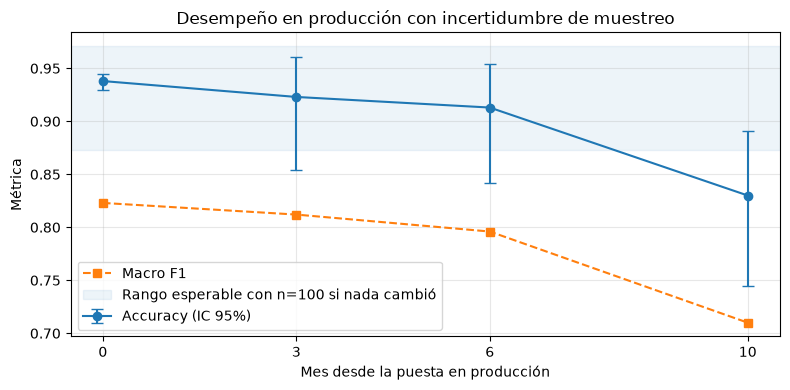

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(met.mes, met.acc, yerr=[met.acc - met.ic_inf, met.ic_sup - met.acc],
            fmt="o-", capsize=4, label="Accuracy (IC 95%)")
ax.plot(met.mes, met.f1_macro, "s--", label="Macro F1")
ax.axhspan(*wilson(ref.acc, 100), color="tab:blue", alpha=.08,
           label="Rango esperable con n=100 si nada cambió")
ax.set_xlabel("Mes desde la puesta en producción"); ax.set_ylabel("Métrica")
ax.set_xticks(met.mes); ax.legend(loc="lower left"); ax.grid(alpha=.3)
ax.set_title("Desempeño en producción con incertidumbre de muestreo")
plt.tight_layout(); plt.show()

## 2) ¿Cuánto varía el **Macro F1** con solo 100 casos?

El Macro F1 promedia el F1 de cada clase. Con 79 clases desbalanceadas, una muestra de 100 casos trae muchas clases con 0, 1 o 2 ejemplos, y un solo error mueve mucho la métrica.

Lo simulo con las predicciones reales del clasificador de la Pregunta 1: tomo miles de muestras de 100 casos del set de test, **sin ningún cambio en los datos**, y miro cuánto varían las métricas solo por azar.

In [18]:
ruta = "data/test_predicciones.csv"
if os.path.exists(ruta):
    pred = pd.read_csv(ruta, dtype={"cod_final": str, "pred": str})
    rng = np.random.default_rng(42)
    sims = []
    for _ in range(3000):
        m = pred.sample(100, random_state=rng.integers(1e9))
        sims.append({"acc": accuracy_score(m.cod_final, m.pred),
                     "f1_macro": f1_score(m.cod_final, m.pred, average="macro"),
                     "clases_en_muestra": m.cod_final.nunique()})
    sims = pd.DataFrame(sims)
    print(f"Modelo de la P1 en el test completo: acc={accuracy_score(pred.cod_final, pred.pred):.3f}, "
          f"F1 macro={f1_score(pred.cod_final, pred.pred, average='macro'):.3f}")
    print(sims.describe(percentiles=[.025, .5, .975]).round(3).loc[["mean", "std", "2.5%", "50%", "97.5%"]])
else:
    print("No está data/test_predicciones.csv (se genera en la Pregunta 1). Se omite la simulación.")

Modelo de la P1 en el test completo: acc=0.917, F1 macro=0.785
         acc  f1_macro  clases_en_muestra
mean   0.918     0.816             31.725
std    0.027     0.067              2.952
2.5%   0.860     0.680             26.000
50%    0.920     0.818             32.000
97.5%  0.970     0.943             38.000


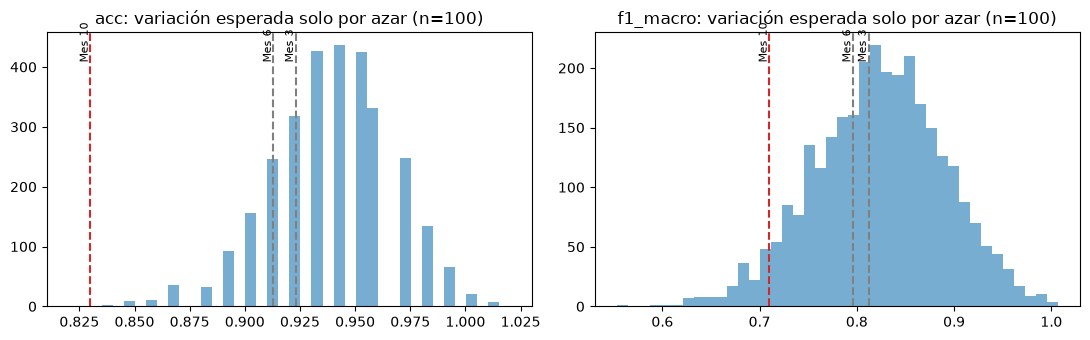

In [19]:
if os.path.exists(ruta):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, col in zip(axs, ["acc", "f1_macro"]):
        # centramos la simulación en el valor de testing del enunciado para comparar formas, no niveles
        desplaz = sims[col] - sims[col].mean() + met.loc[0, col]
        ax.hist(desplaz, bins=40, alpha=.6)
        for _, r in met.iloc[1:].iterrows():
            ax.axvline(r[col], color="tab:red" if r.periodo == "Mes 10" else "gray", ls="--")
            ax.text(r[col], ax.get_ylim()[1]*.9, r.periodo, rotation=90, fontsize=8, ha="right")
        ax.set_title(f"{col}: variación esperada solo por azar (n=100)")
    plt.tight_layout(); plt.show()

### Lectura de los números

- **Meses 3 y 6:** quedan dentro del rango esperable por azar (IC 95% de 0,85 a 0,96; p‑valores 0,54 y 0,31). **No hay evidencia de degradación todavía**: reentrenar ahí sería sobre‑reaccionar al ruido.
- **Mes 10:** la accuracy de 0,83 cae fuera del intervalo (z = 4,3; p < 0,001). **Es un cambio real.**
- **El Macro F1 casi no sirve para monitorear con n=100.** En la simulación con mi propio clasificador, sin ningún cambio en los datos:
  - su desviación estándar es **0,067**, unas 2,5 veces la de la accuracy (0,027);
  - su rango del 95% va de ~0,68 a ~0,94;
  - una muestra de 100 casos trae en promedio **solo 32 de las 79 clases**.

  Por eso el 0,71 del mes 10 queda **en el borde** de lo esperable por azar. Con el Macro F1 solo, la caída ni siquiera se detectaría con seguridad: la alarma la da la accuracy.
- **Brecha accuracy − Macro F1:** se mantiene estable (~0,11‑0,12). La caída del mes 10 parece **transversal**: también afecta a las clases frecuentes y no solo a las pequeñas.
- **Forma de la curva:** una meseta compatible con ruido y luego un **quiebre**, no un desgaste lineal. Eso apunta a un evento o cambio puntual entre los meses 6 y 10.


## 3) Hipótesis

Ordenadas por plausibilidad en el contexto (encuestas de empleo, codificación de actividad económica):

1. **Cambio en la composición de los datos (label shift o estacionalidad).** El empleo es estacional: cosecha agrícola, comercio de fin de año, turismo de verano. Si el mes 10 cae en otra temporada que los datos de entrenamiento, cambia la mezcla de actividades y crecen clases donde el modelo es más débil.
2. **Cambio en el texto de entrada (covariate shift o data drift).** Puede haber:
   - ocupaciones o vocabulario nuevos: plataformas, apps de reparto, nuevos rubros;
   - un cambio del cuestionario o de la forma de preguntar;
   - encuestadores nuevos con otro estilo de registro (más abreviado, otras palabras).

   El modelo, basado en bolsa de palabras, no generaliza a vocabulario que no vio.
3. **Cambio del concepto o de la etiqueta (concept drift).** Puede haber una nueva versión del clasificador de actividades, nuevas instrucciones a los codificadores o un cambio en el equipo que etiqueta la muestra de monitoreo. En ese caso la "verdad" se movió aunque el modelo no.
4. **Un problema de pipeline.** Por ejemplo cambios de encoding (tildes), campos truncados o vacíos, o columnas reordenadas aguas arriba. Producen exactamente un quiebre abrupto y son los más baratos de descartar, así que **se revisan primero**.

## 4) Estrategia de mitigación (sin implementar)

**A. Diagnosticar antes de reentrenar.** Cada hipótesis tiene una solución distinta.

| Hipótesis | Cómo verificarla |
|---|---|
| Pipeline | Comparar el largo de los textos, el % de campos vacíos y los caracteres extraños (encoding) entre el mes 10 y el entrenamiento |
| Composición o estacionalidad | Comparar la distribución de clases reales del mes 10 contra el entrenamiento (chi² o PSI) y revisar el mismo mes del año anterior |
| Data drift | Medir el % de palabras fuera del vocabulario y la distancia entre embeddings de los textos nuevos y los de entrenamiento, y ver si cae el margen o confianza del modelo |
| Concept drift | Hacer un re‑etiquetado ciego de una submuestra por otro codificador y revisar los cambios del manual o del clasificador |

En todos los casos se mira la **matriz de confusión del mes 10**: si los errores se concentran en pocas clases o pares, se sabe dónde actuar.

**B. Monitoreo continuo, aun sin etiquetas.**
- Hay indicadores que no necesitan etiquetado manual y se pueden calcular sobre **todos** los registros, todos los meses:
  - la distribución de clases predichas;
  - la confianza o margen medio y el % de casos de baja confianza;
  - el % de vocabulario nuevo.
- Se definen umbrales de alerta. Así no hay que esperar 10 meses para detectar el problema.

**C. Mejor muestra de evaluación.**
- Aumentar el n, o acumular meses con ventanas móviles, para tener intervalos de confianza útiles.
- Estratificar por clase o por nivel de confianza, sobremuestreando los casos dudosos (muestreo de aprendizaje activo), para que cada etiqueta manual aporte más información.

**D. Reentrenamiento controlado.**
- Incorporar los datos recién etiquetados, dando más peso a lo reciente sin descartar lo antiguo, para no perder las actividades estacionales.
- Validar el modelo nuevo contra el actual en los mismos datos recientes (champion/challenger) antes de reemplazarlo.
- Definir una política de reentrenamiento periódica o gatillada por las alertas.

**E. Humano en el loop.**
- Mientras se corrige el modelo, enviar a codificación manual los casos de baja confianza. Así se protege la calidad del dato publicado, que en una oficina de estadística es lo crítico.
- Esos casos además se convierten en las mejores etiquetas nuevas para reentrenar.

**F. Si es concept drift por un cambio de clasificador:** reentrenar con los datos antiguos no sirve. Hay que re‑etiquetar o mapear el set de entrenamiento al criterio nuevo.

---

# Pregunta 3 – Procesando texto

**Objetivo:** generar, para cada noticia de la tabla `noticias` (MySQL), un resumen de **máximo 50 palabras**.

**Enfoque:**
1. Leer la tabla `noticias` (columnas `titular`, `cuerpo`) desde MySQL a un DataFrame de pandas.
2. Llamar a la **Responses API de OpenRouter** (`POST https://openrouter.ai/api/v1/responses`) con el modelo `google/gemini-2.5-flash-lite`, con el razonamiento desactivado (`reasoning: {"effort": "none"}`) para minimizar coste y latencia.
3. Validar en Python que cada resumen tenga ≤ 50 palabras (si no, se reintenta y, en último caso, se recorta).
4. Guardar el resultado en una columna `resumen` junto con su conteo de palabras `n_palabras`.

## 1. API key de OpenRouter

Según el enunciado, la clave está publicada en un archivo de OneDrive y **puede cambiar**. Por eso el notebook no la copia en ninguna parte: la **lee desde ese archivo** y la vuelve a leer cuando hace falta.

1. **Fuente principal:** el archivo oficial del enunciado (enlace de OneDrive con `?download=1`, que entrega el texto plano). Se guarda en caché 5 minutos para no descargarla en cada llamada.
2. **Respaldo,** si el archivo no está disponible: Secrets de Colab (`OPENROUTER_API_KEY`), luego un archivo `.env` y por último `getpass`.
3. **Rotación:** si OpenRouter rechaza la clave (401/403), se fuerza una nueva lectura del archivo y se reintenta una vez. Así un cambio de clave en medio de la ejecución se resuelve solo.

La clave nunca se imprime ni se guarda en el notebook.

In [20]:
import os, time
from getpass import getpass
import requests

URL_CLAVE = "https://1drv.ms/t/c/3ba457a6b989f5e0/IQDYUbsfa5KwRabKDXrJB9GGAY6PvDqj2Vhr9u0H_xcoNRg?download=1&e=3TGQPe"
_cache = {"clave": None, "t": 0.0, "fuente": None}
TTL = 300  # segundos

def _desde_archivo_oficial():
    r = requests.get(URL_CLAVE, timeout=20)
    r.raise_for_status()
    clave = r.text.strip()
    return clave if clave.startswith("sk-or-") else None

def _desde_respaldos():
    try:
        from google.colab import userdata
        clave = userdata.get("OPENROUTER_API_KEY")
        if clave:
            return clave.strip(), "Secrets de Colab"
    except Exception:
        pass
    try:
        from dotenv import load_dotenv
        load_dotenv(override=True)
    except ImportError:
        pass
    clave = os.environ.get("OPENROUTER_API_KEY", "").strip()
    if clave:
        return clave, ".env / variable de entorno"
    return getpass("Introduce tu OPENROUTER_API_KEY: ").strip(), "ingresada a mano"

def obtener_api_key(forzar=False):
    """Devuelve la clave vigente. forzar=True ignora la caché (se usa cuando la API rechaza la clave)."""
    if not forzar and _cache["clave"] and time.time() - _cache["t"] < TTL:
        return _cache["clave"]
    try:
        clave, fuente = _desde_archivo_oficial(), "archivo del enunciado (OneDrive)"
    except Exception:
        clave = None
    if not clave:
        clave, fuente = _desde_respaldos()
    _cache.update(clave=clave, t=time.time(), fuente=fuente)
    return clave

obtener_api_key()
print("API key cargada desde:", _cache["fuente"])

API key cargada desde: archivo del enunciado (OneDrive)


## 2. Lectura de las noticias desde MySQL

In [21]:
import os, time
import mysql.connector
import pandas as pd

DB = dict(host="sql.freedb.tech", port=3306, user="u_y8tlWZ",
          password="wSkxw3xbhsQg", database="freedb_N4nnid0a")

def leer_noticias(reintentos=10, ruta="data/noticias.csv"):
    """La base es compartida y suele rechazar conexiones (max_user_connections):
    reintenta con espera exponencial y, si no lo logra, usa la copia CSV de respaldo."""
    for i in range(reintentos):
        try:
            cnx = mysql.connector.connect(**DB, connection_timeout=20)
            try:
                cur = cnx.cursor()
                cur.execute("SELECT * FROM noticias")
                df = pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description])
            finally:
                cnx.close()
            os.makedirs("data", exist_ok=True)
            df.to_csv(ruta, index=False)
            print("Leído desde MySQL")
            return df
        except mysql.connector.Error as e:
            espera = min(5 * 1.5 ** i, 30)
            print(f"intento {i+1}: {e.msg[:60]} -> reintento en {espera:.0f}s")
            time.sleep(espera)
    print(f"MySQL no disponible: usando respaldo {ruta}")
    return pd.read_csv(ruta)

df = leer_noticias()
print(df.shape)
df

Leído desde MySQL
(10, 2)


,cuerpo,titular
0,fue rodríguez zapatero el que empezó a utilizar la expresión geometría varia...,escenas de geometría variable
1,la reunión que mantendrán este viernes el diputado y secretario general de p...,iglesias se reunirá con junqueras sin cristal y sin límite de tiempo
2,"bankia abona este jueves, 11 de abril, su quinto dividendo desde que se cons...","bankia paga otros 219 millones al estado vía dividendo, el mayor de su historia"
3,independientemente de los pactos a los que llegue pedro sánchez para seguir ...,sánchez tiene ya una mayoría en el congreso para derogar la reforma laboral ...
4,"de los amigos me guarde dios, que de mis enemigos ya me libro yo. son los re...",un presidente irresponsable
5,"el juez del caso nóos, josé castro, ha ordenado hoy el embargo de la mitad d...",castro embarga el palacete y otra finca a matas para cubrir su fianza en nóos
6,"el presidente del gobierno y del pp, mariano rajoy, se declaró dispuesto a r...","el jefe del ejecutivo, dispuesto a reunirse con pablo iglesias si se lo pide"
7,"el juicio al procés en el tribunal supremo casi tiene fecha cerrada, y los 1...",el último choque con puigdemont y las diferencias entre defensas la cuenta a...
8,"solo tiene 42 años, era un policía de raza», que llevaba la uip grabada a fu...",interior jubila al policía que perdió la visión tras los disturbios del procés»
9,"el coordinador general de eh bildu, arnaldo otegi, ha reaccionado a la decis...","otegi sobre bateragune ""ni nos domaron, ni nos doblaron, ni nos van a domest..."


## 3. Función de resumen con la Responses API

In [22]:
import time
import requests

URL = "https://openrouter.ai/api/v1/responses"
MODELO = "google/gemini-2.5-flash-lite"
MAX_PALABRAS = 50

PROMPT = """Resume la siguiente noticia en español en un máximo de {n} palabras.
Reglas:
- Usa solo hechos que aparezcan en el texto; no inventes ni añadas opiniones.
- Incluye lo esencial: qué ocurrió, quién, dónde y cuándo (si aparece).
- Devuelve únicamente el resumen, en un solo párrafo, sin títulos ni viñetas.

Noticia:
{texto}"""


def contar_palabras(texto):
    return len(texto.split())


def _post(payload):
    """POST a la Responses API. Si la clave es rechazada, relee el archivo oficial y reintenta una vez."""
    for forzar in (False, True):
        headers = {"Authorization": f"Bearer {obtener_api_key(forzar=forzar)}",
                   "Content-Type": "application/json"}
        r = requests.post(URL, headers=headers, json=payload, timeout=60)
        if r.status_code not in (401, 403):
            return r
        print("  La API rechazó la clave: releyendo el archivo de la clave…")
    raise PermissionError(f"OpenRouter rechazó la API key ({r.status_code}) incluso tras releerla. "
                          "Revisa el archivo de la clave, Secrets de Colab o .env.")


def llamar_api(texto, n=MAX_PALABRAS, reintentos=3):
    """Envía una petición a la Responses API con reintentos simples."""
    payload = {
        "model": MODELO,
        "input": PROMPT.format(n=n, texto=texto),
        "reasoning": {"effort": "none"},  # razonamiento desactivado (menor coste)
        "temperature": 0.2,               # salida estable y fiel al texto
        "max_output_tokens": 200,         # margen suficiente para ~50 palabras
    }
    for intento in range(1, reintentos + 1):
        try:
            response = _post(payload)
            response.raise_for_status()
            return response.json()["output"][0]["content"][0]["text"].strip()
        except PermissionError:
            raise
        except Exception as e:
            print(f"  Error (intento {intento}/{reintentos}): {e}")
            if intento == reintentos:
                raise
            time.sleep(2 * intento)  # espera creciente antes de reintentar


def resumir(texto):
    """Resume una noticia garantizando un máximo de 50 palabras."""
    resumen = llamar_api(texto)
    if contar_palabras(resumen) > MAX_PALABRAS:
        # Un reintento pidiendo un resumen más corto
        resumen = llamar_api(texto, n=40)
    if contar_palabras(resumen) > MAX_PALABRAS:
        # Último recurso: recorte duro a 50 palabras
        resumen = " ".join(resumen.split()[:MAX_PALABRAS]).rstrip(",;:") + "…"
    return resumen

## 4. Aplicar a todas las noticias

In [23]:
resumenes = []
for i, fila in df.iterrows():
    print(f"Resumiendo noticia {i + 1}/{len(df)}: {fila['titular'][:60]}")
    # Se pasa el titular como contexto junto con el cuerpo
    resumenes.append(resumir(f"{fila['titular']}\n\n{fila['cuerpo']}"))

df["resumen"] = resumenes
df["n_palabras"] = df["resumen"].apply(contar_palabras)

pd.set_option("display.max_colwidth", None)
df[["titular", "resumen", "n_palabras"]]

Resumiendo noticia 1/10: escenas de geometría variable


Resumiendo noticia 2/10: iglesias se reunirá con junqueras sin cristal y sin límite d


Resumiendo noticia 3/10: bankia paga otros 219 millones al estado vía dividendo, el m


Resumiendo noticia 4/10: sánchez tiene ya una mayoría en el congreso para derogar la 


Resumiendo noticia 5/10: un presidente irresponsable


Resumiendo noticia 6/10: castro embarga el palacete y otra finca a matas para cubrir 


Resumiendo noticia 7/10: el jefe del ejecutivo, dispuesto a reunirse con pablo iglesi


Resumiendo noticia 8/10: el último choque con puigdemont y las diferencias entre defe


Resumiendo noticia 9/10: interior jubila al policía que perdió la visión tras los dis


Resumiendo noticia 10/10: otegi sobre bateragune "ni nos domaron, ni nos doblaron, ni 


,titular,resumen,n_palabras
0,escenas de geometría variable,"Sánchez utiliza la ""geometría variable"" para gobernar, buscando alianzas coyunturales con nacionalistas, separatistas y ciudadanos. Aunque UP muestra incomodidad, Cs apoya al gobierno. Otros socios negociarán su apoyo, mientras el gobierno confía en su estrategia, a pesar de posibles imprevistos económicos o judiciales.",43
1,iglesias se reunirá con junqueras sin cristal y sin límite de tiempo,"Pablo Iglesias se reunirá con Oriol Junqueras este viernes en la cárcel de Lledoners (Barcelona). La reunión, sin cristal y sin límite de tiempo, abordará la situación de los políticos catalanes presos y buscará el apoyo de ERC a los presupuestos.",41
2,"bankia paga otros 219 millones al estado vía dividendo, el mayor de su historia","Bankia pagó 219 millones de euros al Estado el 11 de abril como dividendo, el mayor de su historia. Esto eleva a 961 millones la devolución total por esta vía. El Estado posee el 61,4% de la entidad.",38
3,"sánchez tiene ya una mayoría en el congreso para derogar la reforma laboral y la ""ley mordaza ""","El nuevo Congreso tiene mayoría de izquierdas para derogar la reforma laboral y la ""ley mordaza"". Pedro Sánchez podrá tramitar la ley de eutanasia y otras propuestas progresistas, dependiendo de su voluntad política y el calendario legislativo.",37
4,un presidente irresponsable,"Don Juan Carlos ha regularizado casi 4,5 millones de euros ante Hacienda por viajes en jet privado pagados por una fundación. Anteriormente, abonó 680.000 euros por dádivas de un empresario. El presidente del gobierno, Pedro Sánchez, rechaza sus conductas incívicas.",40
5,castro embarga el palacete y otra finca a matas para cubrir su fianza en nóos,"El juez José Castro embargó el palacete y otra finca de Jaume Matas en Palma para cubrir su fianza de 3,5 millones de euros en el caso Nóos. El embargo se realizó hoy, al concluir el plazo para que los acusados informaran de sus bienes embargables.",46
6,"el jefe del ejecutivo, dispuesto a reunirse con pablo iglesias si se lo pide","Mariano Rajoy, presidente del gobierno, se mostró dispuesto a reunirse con Pablo Iglesias, líder de Podemos, si este lo solicita. Rajoy afirmó que habla con todos y atribuyó su falta de encuentro previo a sus diferentes ámbitos de trabajo.",39
7,el último choque con puigdemont y las diferencias entre defensas la cuenta atrás para el juicio al procés,"El juicio del procés comenzará la semana del 5 de febrero en el Tribunal Supremo. Doce acusados y sus defensas preparan sus estrategias, mientras las diferencias entre partidos independentistas y el gobierno marcan la cuenta atrás. El juicio se desarrollará cerca de las elecciones de mayo.",46
8,interior jubila al policía que perdió la visión tras los disturbios del procés»,El Ministerio del Interior ha jubilado a un agente de la UIP de 42 años que perdió la visión tras ser herido por un objeto en Barcelona durante los disturbios del procés. Las lesiones le impiden continuar en el servicio policial.,41
9,"otegi sobre bateragune ""ni nos domaron, ni nos doblaron, ni nos van a domesticar""","Arnaldo Otegi reaccionó al nuevo juicio ordenado por el Tribunal Supremo por pertenencia a organización terrorista, tuiteando ""¡ni nos domaron, ni nos doblaron, ni nos van a domesticar!"". El Supremo anuló la sentencia de 2012 por vulneración del TEDH.",39


In [24]:
assert (df["n_palabras"] <= MAX_PALABRAS).all(), "Hay resúmenes con más de 50 palabras"
print(f"OK: todos los resúmenes tienen ≤ {MAX_PALABRAS} palabras "
      f"(máx = {df['n_palabras'].max()}, media = {df['n_palabras'].mean():.1f})")

OK: todos los resúmenes tienen ≤ 50 palabras (máx = 46, media = 41.0)


## 5. Reporte automático de calidad y sugerencias

Que el resumen tenga 50 palabras o menos no garantiza que sea **bueno**. Evalúo cada resumen de dos formas complementarias:

1. **Métricas determinísticas,** baratas y reproducibles:
   - **Compresión:** palabras del resumen / palabras del cuerpo.
   - **Fidelidad léxica:** % de palabras de contenido del resumen que aparecen en la noticia. Si es bajo, el modelo pudo agregar información.
   - **Números:** cifras y fechas de la noticia que se conservan en el resumen, y **cifras del resumen que no están en la noticia**. Estas últimas son una señal fuerte de alucinación.
2. **LLM como evaluador (LLM-as-a-judge):** el mismo modelo califica de 1 a 5 la fidelidad, la cobertura y la claridad, y propone una mejora concreta.
   - *Limitación:* un modelo que evalúa sus propios resúmenes tiende a ser indulgente. Por eso el puntaje se cruza con las métricas determinísticas y no se usa solo.

Con todo eso se generan **sugerencias automáticas por regla** y un archivo `reporte_resumenes.md`.

In [25]:
import re, json, unicodedata

STOP = set("""a al algo ante con contra de del desde durante e el en entre era es esta este esto ha han hasta la las le les lo los mas me mi muy no nos o para pero por que se sin sobre su sus tambien tras un una uno unos unas y ya fue son ser sera estos estas como cual donde cuando tiene tienen""".split())

def tokens_norm(t):
    t = unicodedata.normalize("NFKD", str(t).lower()).encode("ascii", "ignore").decode()
    return re.findall(r"[a-z0-9]+", t)

def numeros(t):
    return set(re.findall(r"\d+(?:[.,]\d+)?", str(t)))

def metricas(cuerpo, resumen):
    pc, pr = tokens_norm(cuerpo), tokens_norm(resumen)
    contenido_r = [w for w in pr if w not in STOP and len(w) > 2]
    vocab_c = set(pc)
    nc, nr = numeros(cuerpo), numeros(resumen)
    return {
        "compresion": round(len(resumen.split()) / max(len(str(cuerpo).split()), 1), 2),
        "fidelidad_lexica": round(sum(w in vocab_c for w in contenido_r) / max(len(contenido_r), 1), 2),
        "numeros_conservados": f"{len(nc & nr)}/{len(nc)}",
        "numeros_inventados": sorted(nr - nc),
    }

# se compara contra titular + cuerpo, que es lo que recibió el modelo
met_res = pd.DataFrame([metricas(f"{t} {c}", r) for t, c, r in zip(df["titular"], df["cuerpo"], df["resumen"])])
met_res

,compresion,fidelidad_lexica,numeros_conservados,numeros_inventados
0,0.07,0.55,0/0,[]
1,0.16,0.91,0/0,[]
2,0.12,0.89,4/25,[]
3,0.06,0.83,0/2,[]
4,0.07,0.93,1/3,"[4,5]"
5,0.07,0.92,1/11,[]
6,0.16,0.52,0/0,[]
7,0.05,0.80,1/7,[]
8,0.05,0.67,1/10,[]
9,0.11,0.77,1/3,[]


In [26]:
PROMPT_JUEZ = """Eres un editor exigente. Evalúa el RESUMEN respecto de la NOTICIA original.
Responde SOLO un JSON válido, sin texto adicional, con estas claves:
{{"fidelidad": 1-5, "cobertura": 1-5, "claridad": 1-5,
  "problema": "principal debilidad en <= 15 palabras o 'ninguno'",
  "sugerencia": "mejora concreta en <= 20 palabras"}}
- fidelidad: 5 = todo lo dicho está en la noticia; 1 = hay datos inventados o tergiversados.
- cobertura: 5 = incluye lo esencial (qué, quién, dónde, cuándo); 1 = omite lo central.
- claridad: 5 = se entiende solo, sin leer la noticia.

NOTICIA:
{noticia}

RESUMEN:
{resumen}"""

def juzgar(noticia, resumen):
    payload = {"model": MODELO, "input": PROMPT_JUEZ.format(noticia=noticia, resumen=resumen),
               "reasoning": {"effort": "none"}, "temperature": 0, "max_output_tokens": 200}
    r = _post(payload)
    r.raise_for_status()
    texto = r.json()["output"][0]["content"][0]["text"]
    try:
        return json.loads(re.search(r"\{.*\}", texto, re.S).group())
    except Exception:
        return {"fidelidad": None, "cobertura": None, "claridad": None,
                "problema": "respuesta no parseable", "sugerencia": texto[:100]}

juicios = pd.DataFrame([juzgar(f"{t}\n\n{c}", r)
                        for t, c, r in zip(df["titular"], df["cuerpo"], df["resumen"])])
evaluacion = pd.concat([df[["titular", "n_palabras"]], met_res, juicios], axis=1)
evaluacion

,titular,n_palabras,compresion,fidelidad_lexica,numeros_conservados,numeros_inventados,fidelidad,cobertura,claridad,problema,sugerencia
0,escenas de geometría variable,43,0.07,0.55,0/0,[],4,4,5,Omite la comparación con la legislatura de Zapatero y el rol de UP.,Incluir brevemente la comparación con Zapatero y la incomodidad de UP para mayor contexto.
1,iglesias se reunirá con junqueras sin cristal y sin límite de tiempo,41,0.16,0.91,0/0,[],5,5,5,ninguno,ninguna
2,"bankia paga otros 219 millones al estado vía dividendo, el mayor de su historia",38,0.12,0.89,4/25,[],5,4,5,Omite el contexto de la devolución total de ayudas públicas.,Incluir brevemente que este dividendo contribuye a la devolución de ayudas públicas.
3,"sánchez tiene ya una mayoría en el congreso para derogar la reforma laboral y la ""ley mordaza """,37,0.06,0.83,0/2,[],5,4,5,Omite la mención de otros grupos parlamentarios que suman la mayoría.,"Incluir que la mayoría se forma con PSOE, Unidas Podemos, ERC y Compromís."
4,un presidente irresponsable,40,0.07,0.93,1/3,"[4,5]",5,4,5,Omite la crítica al presidente Sánchez y la comparación con otros líderes.,Incluir la crítica a Sánchez y la comparación con otros líderes para una cobertura más completa.
5,castro embarga el palacete y otra finca a matas para cubrir su fianza en nóos,46,0.07,0.92,1/11,[],5,4,5,Omite otros embargos y fianzas mencionados en la noticia.,Incluir brevemente que el embargo a Matas es parte de un proceso más amplio de embargos a varios acusados.
6,"el jefe del ejecutivo, dispuesto a reunirse con pablo iglesias si se lo pide",39,0.16,0.52,0/0,[],5,3,5,Omite la opinión de Rajoy sobre Podemos y Ciudadanos.,Incluir brevemente la visión de Rajoy sobre Podemos y Ciudadanos para mayor contexto.
7,el último choque con puigdemont y las diferencias entre defensas la cuenta atrás para el juicio al procés,46,0.05,0.80,1/7,[],5,4,5,Omite detalles sobre las diferencias entre defensas y la postura de Vox.,Incluir brevemente las divergencias entre las defensas y la acusación de Vox para mayor exhaustividad.
8,interior jubila al policía que perdió la visión tras los disturbios del procés»,41,0.05,0.67,1/10,[],5,4,5,Omite detalles sobre la gravedad de las lesiones y el impacto en su vida personal.,Incluir que las secuelas afectan su vida diaria y le impiden realizar actividades básicas.
9,"otegi sobre bateragune ""ni nos domaron, ni nos doblaron, ni nos van a domesticar""",39,0.11,0.77,1/3,[],5,4,5,omite la mención de los otros acusados y el motivo de la anulación.,Incluir brevemente los nombres de los otros acusados y el motivo de la anulación por el TEDH.


In [27]:
def sugerencias_globales(ev):
    s = []
    inventados = ev["numeros_inventados"].map(len) > 0
    if inventados.any():
        s.append(f"Hay cifras en los resúmenes que no están en la noticia (noticias {ev.index[inventados].tolist()}). "
                 "Revisarlas a mano y reforzar en el prompt: 'no agregues cifras ni fechas que no aparezcan'.")
    if (ev["fidelidad_lexica"] < 0.8).any():
        s.append("Algunos resúmenes usan bastante vocabulario ausente del original (fidelidad léxica < 0,8). "
                 "No siempre es un error (puede ser parafraseo), pero conviene revisarlos primero.")
    if (pd.to_numeric(ev["cobertura"], errors="coerce") <= 3).any():
        s.append("El evaluador detecta resúmenes que omiten información central. Se puede pedir explícitamente "
                 "'qué, quién, dónde, cuándo' o generar primero una lista de hechos clave y luego el resumen.")
    if ev["n_palabras"].max() >= 48:
        s.append("Hay resúmenes en el límite de 50 palabras: conviene pedir 40-45 para dejar margen "
                 "y evitar el recorte duro.")
    if ev["compresion"].mean() > 0.5:
        s.append("La compresión media es baja (resumen > 50% del cuerpo): para noticias cortas evaluar "
                 "si se necesita resumen o basta el titular.")
    s.append("Para producción: validar con una muestra de resúmenes evaluados por personas y medir el "
             "acuerdo con el juez LLM antes de confiar en él; usar un modelo juez distinto del generador.")
    return s

prom = evaluacion[["fidelidad", "cobertura", "claridad"]].apply(pd.to_numeric, errors="coerce").mean().round(2)
sug = sugerencias_globales(evaluacion)

lineas = ["# Reporte automático – Resúmenes de noticias", "",
          f"- Modelo: `{MODELO}` (razonamiento desactivado)",
          f"- Noticias procesadas: {len(df)} | palabras por resumen: media {df.n_palabras.mean():.1f}, máx {df.n_palabras.max()}",
          f"- Puntaje medio del evaluador (1-5): fidelidad {prom.fidelidad}, cobertura {prom.cobertura}, claridad {prom.claridad}",
          f"- Fidelidad léxica media: {evaluacion.fidelidad_lexica.mean():.2f} | compresión media: {evaluacion.compresion.mean():.2f}",
          "", "## Sugerencias", ""] + [f"{i}. {x}" for i, x in enumerate(sug, 1)] + \
         ["", "## Detalle por noticia", "",
          "| # | Titular | Palabras | Fid. léxica | Núm. inventados | Fid. | Cob. | Clar. | Problema | Sugerencia |",
          "|---|---|---|---|---|---|---|---|---|---|"]
for i, r in evaluacion.iterrows():
    lineas.append(f"| {i} | {r.titular[:45]} | {r.n_palabras} | {r.fidelidad_lexica} | "
                  f"{', '.join(r.numeros_inventados) or '-'} | {r.fidelidad} | {r.cobertura} | {r.claridad} | "
                  f"{r.problema} | {r.sugerencia} |")
lineas += ["", "## Resúmenes", ""] + [f"**{i}. {t}**  \n{r}\n" for i, (t, r) in enumerate(zip(df.titular, df.resumen))]

reporte = "\n".join(lineas)
with open("reporte_resumenes.md", "w", encoding="utf-8") as f:
    f.write(reporte)

from IPython.display import Markdown, display
display(Markdown(reporte))

# Reporte automático – Resúmenes de noticias

- Modelo: `google/gemini-2.5-flash-lite` (razonamiento desactivado)
- Noticias procesadas: 10 | palabras por resumen: media 41.0, máx 46
- Puntaje medio del evaluador (1-5): fidelidad 4.9, cobertura 4.0, claridad 5.0
- Fidelidad léxica media: 0.78 | compresión media: 0.09

## Sugerencias

1. Hay cifras en los resúmenes que no están en la noticia (noticias [4]). Revisarlas a mano y reforzar en el prompt: 'no agregues cifras ni fechas que no aparezcan'.
2. Algunos resúmenes usan bastante vocabulario ausente del original (fidelidad léxica < 0,8). No siempre es un error (puede ser parafraseo), pero conviene revisarlos primero.
3. El evaluador detecta resúmenes que omiten información central. Se puede pedir explícitamente 'qué, quién, dónde, cuándo' o generar primero una lista de hechos clave y luego el resumen.
4. Para producción: validar con una muestra de resúmenes evaluados por personas y medir el acuerdo con el juez LLM antes de confiar en él; usar un modelo juez distinto del generador.

## Detalle por noticia

| # | Titular | Palabras | Fid. léxica | Núm. inventados | Fid. | Cob. | Clar. | Problema | Sugerencia |
|---|---|---|---|---|---|---|---|---|---|
| 0 | escenas de geometría variable | 43 | 0.55 | - | 4 | 4 | 5 | Omite la comparación con la legislatura de Zapatero y el rol de UP. | Incluir brevemente la comparación con Zapatero y la incomodidad de UP para mayor contexto. |
| 1 | iglesias se reunirá con junqueras sin cristal | 41 | 0.91 | - | 5 | 5 | 5 | ninguno | ninguna |
| 2 | bankia paga otros 219 millones al estado vía  | 38 | 0.89 | - | 5 | 4 | 5 | Omite el contexto de la devolución total de ayudas públicas. | Incluir brevemente que este dividendo contribuye a la devolución de ayudas públicas. |
| 3 | sánchez tiene ya una mayoría en el congreso p | 37 | 0.83 | - | 5 | 4 | 5 | Omite la mención de otros grupos parlamentarios que suman la mayoría. | Incluir que la mayoría se forma con PSOE, Unidas Podemos, ERC y Compromís. |
| 4 | un presidente irresponsable | 40 | 0.93 | 4,5 | 5 | 4 | 5 | Omite la crítica al presidente Sánchez y la comparación con otros líderes. | Incluir la crítica a Sánchez y la comparación con otros líderes para una cobertura más completa. |
| 5 | castro embarga el palacete y otra finca a mat | 46 | 0.92 | - | 5 | 4 | 5 | Omite otros embargos y fianzas mencionados en la noticia. | Incluir brevemente que el embargo a Matas es parte de un proceso más amplio de embargos a varios acusados. |
| 6 | el jefe del ejecutivo, dispuesto a reunirse c | 39 | 0.52 | - | 5 | 3 | 5 | Omite la opinión de Rajoy sobre Podemos y Ciudadanos. | Incluir brevemente la visión de Rajoy sobre Podemos y Ciudadanos para mayor contexto. |
| 7 | el último choque con puigdemont y las diferen | 46 | 0.8 | - | 5 | 4 | 5 | Omite detalles sobre las diferencias entre defensas y la postura de Vox. | Incluir brevemente las divergencias entre las defensas y la acusación de Vox para mayor exhaustividad. |
| 8 | interior jubila al policía que perdió la visi | 41 | 0.67 | - | 5 | 4 | 5 | Omite detalles sobre la gravedad de las lesiones y el impacto en su vida personal. | Incluir que las secuelas afectan su vida diaria y le impiden realizar actividades básicas. |
| 9 | otegi sobre bateragune "ni nos domaron, ni no | 39 | 0.77 | - | 5 | 4 | 5 | omite la mención de los otros acusados y el motivo de la anulación. | Incluir brevemente los nombres de los otros acusados y el motivo de la anulación por el TEDH. |

## Resúmenes

**0. escenas de geometría variable**  
Sánchez utiliza la "geometría variable" para gobernar, buscando alianzas coyunturales con nacionalistas, separatistas y ciudadanos. Aunque UP muestra incomodidad, Cs apoya al gobierno. Otros socios negociarán su apoyo, mientras el gobierno confía en su estrategia, a pesar de posibles imprevistos económicos o judiciales.

**1. iglesias se reunirá con junqueras sin cristal y sin límite de tiempo**  
Pablo Iglesias se reunirá con Oriol Junqueras este viernes en la cárcel de Lledoners (Barcelona). La reunión, sin cristal y sin límite de tiempo, abordará la situación de los políticos catalanes presos y buscará el apoyo de ERC a los presupuestos.

**2. bankia paga otros 219 millones al estado vía dividendo, el mayor de su historia**  
Bankia pagó 219 millones de euros al Estado el 11 de abril como dividendo, el mayor de su historia. Esto eleva a 961 millones la devolución total por esta vía. El Estado posee el 61,4% de la entidad.

**3. sánchez tiene ya una mayoría en el congreso para derogar la reforma laboral y la "ley mordaza "**  
El nuevo Congreso tiene mayoría de izquierdas para derogar la reforma laboral y la "ley mordaza". Pedro Sánchez podrá tramitar la ley de eutanasia y otras propuestas progresistas, dependiendo de su voluntad política y el calendario legislativo.

**4. un presidente irresponsable**  
Don Juan Carlos ha regularizado casi 4,5 millones de euros ante Hacienda por viajes en jet privado pagados por una fundación. Anteriormente, abonó 680.000 euros por dádivas de un empresario. El presidente del gobierno, Pedro Sánchez, rechaza sus conductas incívicas.

**5. castro embarga el palacete y otra finca a matas para cubrir su fianza en nóos**  
El juez José Castro embargó el palacete y otra finca de Jaume Matas en Palma para cubrir su fianza de 3,5 millones de euros en el caso Nóos. El embargo se realizó hoy, al concluir el plazo para que los acusados informaran de sus bienes embargables.

**6. el jefe del ejecutivo, dispuesto a reunirse con pablo iglesias si se lo pide**  
Mariano Rajoy, presidente del gobierno, se mostró dispuesto a reunirse con Pablo Iglesias, líder de Podemos, si este lo solicita. Rajoy afirmó que habla con todos y atribuyó su falta de encuentro previo a sus diferentes ámbitos de trabajo.

**7. el último choque con puigdemont y las diferencias entre defensas la cuenta atrás para el juicio al procés**  
El juicio del procés comenzará la semana del 5 de febrero en el Tribunal Supremo. Doce acusados y sus defensas preparan sus estrategias, mientras las diferencias entre partidos independentistas y el gobierno marcan la cuenta atrás. El juicio se desarrollará cerca de las elecciones de mayo.

**8. interior jubila al policía que perdió la visión tras los disturbios del procés»**  
El Ministerio del Interior ha jubilado a un agente de la UIP de 42 años que perdió la visión tras ser herido por un objeto en Barcelona durante los disturbios del procés. Las lesiones le impiden continuar en el servicio policial.

**9. otegi sobre bateragune "ni nos domaron, ni nos doblaron, ni nos van a domesticar"**  
Arnaldo Otegi reaccionó al nuevo juicio ordenado por el Tribunal Supremo por pertenencia a organización terrorista, tuiteando "¡ni nos domaron, ni nos doblaron, ni nos van a domesticar!". El Supremo anuló la sentencia de 2012 por vulneración del TEDH.


### Lectura del reporte

> Las cifras exactas están en el reporte generado arriba (`reporte_resumenes.md`) y **varían entre ejecuciones**. Aquí dejo solo las conclusiones que se repitieron en las tres ejecuciones que hice.

**Requisito cumplido:** todos los resúmenes quedan en 50 palabras o menos. Sin embargo, aun con temperatura 0,2 **los resúmenes no son idénticos entre ejecuciones**, y varios llegan a 47–49 palabras. Pedir 40–45 palabras daría margen y evitaría depender del recorte.

**Lo que dicen las métricas:**
- **El problema típico es omitir, no inventar.** El juez da siempre una fidelidad cercana a 5 y una cobertura más baja (~3,8–3,9). Con 50 palabras para noticias de cientos de palabras, el modelo deja fuera matices, otros actores o el contexto.
- **La alerta de cifra inventada en la noticia 4 es un falso positivo.** El original dice "casi cuatro millones y medio" en palabras y el resumen escribe "4,5". El detector no normaliza números escritos con palabras; hay que mejorarlo, por ejemplo con `text2num`, antes de usarlo como alarma automática.
- **Una fidelidad léxica baja no implica error.** En las noticias de opinión o con muchos actores (0, 6 y 7 en todas las ejecuciones) el modelo parafrasea y nombra entidades de forma explícita, por ejemplo "Mariano Rajoy" cuando el texto dice "el jefe del ejecutivo". La métrica sirve para priorizar qué revisar, no para juzgar.
- **Las columnas de opinión son un caso especial.** Las noticias 0 y 4 son editoriales: el titular expresa una postura ("un presidente irresponsable") y el resumen la neutraliza. Hay que decidir si el resumen debe reportar hechos o representar el argumento del autor. Es una definición de negocio, no un ajuste técnico.

**Sugerencias:**
1. Para mejorar la cobertura sin pasar el límite: extraer primero los hechos clave (qué, quién, dónde, cuándo y por qué) y luego redactar el resumen.
2. Distinguir el tipo de texto (noticia u opinión) y usar un prompt distinto para cada uno.
3. Calibrar el juez LLM con una muestra evaluada por personas, y usar como juez un modelo distinto del generador.
4. Normalizar los números escritos en palabras en el detector de cifras.
5. Si se necesita reproducibilidad (por ejemplo, para auditar), usar temperatura 0 y guardar cada resumen con la versión del modelo y la fecha.


## 6. Notas de diseño

- **Temperatura baja (0.2):** en resumen queremos fidelidad al texto y resultados reproducibles, no creatividad; reduce el riesgo de alucinaciones.
- **Validación posterior del nº de palabras:** los LLM no cuentan palabras con exactitud, así que el límite de 50 se comprueba en Python. Si se supera, se pide un resumen más corto (40 palabras) y, como último recurso, se recorta. El `assert` final garantiza el requisito.
- **`max_output_tokens = 200`:** 50 palabras en español son ~70-90 tokens; el margen evita respuestas cortadas sin permitir salidas largas.
- **Coste:** modelo ligero (`gemini-2.5-flash-lite`), razonamiento desactivado con `reasoning: {"effort": "none"}` (según la guía de *reasoning tokens* de OpenRouter, `effort`/`enabled`/`max_tokens` funcionan igual en Responses y Chat Completions), una sola llamada por noticia en el caso normal y solo 10 noticias: el coste total es de fracciones de céntimo.
- **Robustez:** `timeout` en cada petición y reintentos con espera creciente ante errores de red o de la API (p. ej. 429/5xx).
- **Seguridad:** la API key se lee de los Secrets de Colab o se introduce con `getpass`; nunca queda en el código.

---

# Pregunta 4 – Cuéntanos sobre un proyecto

El contenido de la respuesta se escribe en las celdas de Python de abajo: una variable por sección, en formato Markdown.
Cada celda muestra su sección formateada y la última celda **genera automáticamente `pregunta4_proyecto.md`** con la respuesta completa.

In [28]:
from datetime import date
from IPython.display import Markdown, display

secciones = {}  # título de la sección -> contenido en Markdown

def seccion(titulo, texto):
    """Registra una sección de la respuesta y la muestra formateada."""
    secciones[titulo] = texto.strip()
    display(Markdown(f"## {titulo}\n\n{texto.strip()}"))

In [29]:
PROYECTO = "Notas de Campo: clasificación y priorización editorial de noticias ambientales con reglas + LLM"

seccion("Contexto", """
- **Proyecto:** Notas de Campo, la línea editorial asistida por IA que uso para generar contenido de LinkedIn e Instagram para ICTA (mi consultora) y para mi marca personal.
- **Mi rol:** diseñé la solución completa: arquitectura, taxonomía, reglas, criterios de evaluación y flujo de revisión. El código lo construí en conjunto con asistentes de IA, iterando y corrigiendo.
- **Stack:**
  - TypeScript sobre Cloudflare Workers + D1 (SQLite), desplegado y en uso continuo;
  - Workers AI (Llama 3.3 70B) para evaluar;
  - la API de Claude para redactar borradores.
""")

## Contexto

- **Proyecto:** Notas de Campo, la línea editorial asistida por IA que uso para generar contenido de LinkedIn e Instagram para ICTA (mi consultora) y para mi marca personal.
- **Mi rol:** diseñé la solución completa: arquitectura, taxonomía, reglas, criterios de evaluación y flujo de revisión. El código lo construí en conjunto con asistentes de IA, iterando y corrigiendo.
- **Stack:**
  - TypeScript sobre Cloudflare Workers + D1 (SQLite), desplegado y en uso continuo;
  - Workers AI (Llama 3.3 70B) para evaluar;
  - la API de Claude para redactar borradores.

In [30]:
seccion("1. Problema de negocio", """
- **Situación:** para alimentar las redes de ICTA y las mías sigo unas 25 fuentes de noticias ambientales (RSS y sitios web). Revisarlas a mano me tomaba varias horas a la semana, y mi criterio para elegir qué publicar no era constante: cambiaba según el día.
- **Tarea a automatizar:**
  1. clasificar cada artículo en una taxonomía de **26 categorías** (agua, sequía, incendios, SEIA, minería…);
  2. priorizarlo;
  3. sugerir una **ruta editorial**: señal, post técnico, opinión, caso aplicado, boletín o revisión manual.
- **Restricción:** *nada se publica solo.* El sistema clasifica, evalúa y propone; yo apruebo.
- **Éxito:** menos horas de revisión y más contenido publicado de forma regular.
""")

## 1. Problema de negocio

- **Situación:** para alimentar las redes de ICTA y las mías sigo unas 25 fuentes de noticias ambientales (RSS y sitios web). Revisarlas a mano me tomaba varias horas a la semana, y mi criterio para elegir qué publicar no era constante: cambiaba según el día.
- **Tarea a automatizar:**
  1. clasificar cada artículo en una taxonomía de **26 categorías** (agua, sequía, incendios, SEIA, minería…);
  2. priorizarlo;
  3. sugerir una **ruta editorial**: señal, post técnico, opinión, caso aplicado, boletín o revisión manual.
- **Restricción:** *nada se publica solo.* El sistema clasifica, evalúa y propone; yo apruebo.
- **Éxito:** menos horas de revisión y más contenido publicado de forma regular.

In [31]:
seccion("2. Estrategia utilizada", """
**Dos capas, de lo barato y explicable a lo costoso:**

1. **Clasificación por reglas:** palabras clave con sinónimos y **exclusiones** para evitar falsos positivos, más un puntaje y una ruta sugerida. Es explicable, sin costo y filtra el volumen. En una corrida de 265 artículos, 128 quedaron para revisión manual.
2. **Evaluación con LLM en 13 dimensiones**, por ejemplo relevancia territorial, novedad, necesidad de verificación y riesgo reputacional:
   - el modelo responde un **JSON validado contra un esquema** (enteros de 0 a 5);
   - el **total se calcula en código**, no lo decide el modelo;
   - si la salida no valida, el artículo **cae a revisión manual** y queda registrado.

   Después, el LLM propone ángulos y Claude redacta borradores editables.

**Decisiones clave:**
- **Reglas antes que LLM,** como línea base y filtro.
- **Un modelo por tarea:** uno barato para evaluar, que es una tarea estructurada, y uno más fuerte en español para redactar.
- **Tope de costo diario** de evaluaciones.
- **Revisión humana obligatoria** en un panel de aprobación antes de publicar.
""")

## 2. Estrategia utilizada

**Dos capas, de lo barato y explicable a lo costoso:**

1. **Clasificación por reglas:** palabras clave con sinónimos y **exclusiones** para evitar falsos positivos, más un puntaje y una ruta sugerida. Es explicable, sin costo y filtra el volumen. En una corrida de 265 artículos, 128 quedaron para revisión manual.
2. **Evaluación con LLM en 13 dimensiones**, por ejemplo relevancia territorial, novedad, necesidad de verificación y riesgo reputacional:
   - el modelo responde un **JSON validado contra un esquema** (enteros de 0 a 5);
   - el **total se calcula en código**, no lo decide el modelo;
   - si la salida no valida, el artículo **cae a revisión manual** y queda registrado.

   Después, el LLM propone ángulos y Claude redacta borradores editables.

**Decisiones clave:**
- **Reglas antes que LLM,** como línea base y filtro.
- **Un modelo por tarea:** uno barato para evaluar, que es una tarea estructurada, y uno más fuerte en español para redactar.
- **Tope de costo diario** de evaluaciones.
- **Revisión humana obligatoria** en un panel de aprobación antes de publicar.

In [32]:
seccion("3. Reflexión y aprendizaje", """
**Tres problemas reales me obligaron a cambiar el diseño:**
- **El LLM devolvía JSON mal formado o con valores fuera de rango.** Lo resolví forzando un esquema, validando en código y enviando lo inválido a revisión manual.
- **La evaluación podía disparar costos o agotar la cuota.** Lo resolví con un tope diario.
- **Con solo título y resumen, los borradores salían genéricos.** Tuve que entregarle a Claude el texto completo de forma transitoria.

La lección: **la salida de un LLM es un dato no confiable.** Hay que validarla, acotarla y tener una ruta de escape hacia una persona. Es la misma lógica que veo para codificar respuestas abiertas: automatizar lo seguro y derivar lo dudoso.

**Lo que haría distinto:** juzgué el éxito por el tiempo ahorrado y el contenido publicado, pero nunca etiqueté una muestra para medir la calidad de la clasificación. Sin eso no puedo cuantificar cuánto aporta el LLM sobre las reglas.

**Consejo para quien empieza:**
1. definir la métrica y una muestra etiquetada antes de elegir el modelo;
2. construir una línea base simple;
3. diseñar desde el inicio qué pasa cuando el modelo falla o duda.
""")

## 3. Reflexión y aprendizaje

**Tres problemas reales me obligaron a cambiar el diseño:**
- **El LLM devolvía JSON mal formado o con valores fuera de rango.** Lo resolví forzando un esquema, validando en código y enviando lo inválido a revisión manual.
- **La evaluación podía disparar costos o agotar la cuota.** Lo resolví con un tope diario.
- **Con solo título y resumen, los borradores salían genéricos.** Tuve que entregarle a Claude el texto completo de forma transitoria.

La lección: **la salida de un LLM es un dato no confiable.** Hay que validarla, acotarla y tener una ruta de escape hacia una persona. Es la misma lógica que veo para codificar respuestas abiertas: automatizar lo seguro y derivar lo dudoso.

**Lo que haría distinto:** juzgué el éxito por el tiempo ahorrado y el contenido publicado, pero nunca etiqueté una muestra para medir la calidad de la clasificación. Sin eso no puedo cuantificar cuánto aporta el LLM sobre las reglas.

**Consejo para quien empieza:**
1. definir la métrica y una muestra etiquetada antes de elegir el modelo;
2. construir una línea base simple;
3. diseñar desde el inicio qué pasa cuando el modelo falla o duda.

## Generar el archivo Markdown

In [33]:
def exportar_md(ruta="pregunta4_proyecto.md"):
    pendientes = [t for t, s in secciones.items() if "PENDIENTE" in s] + (["Nombre"] if "PENDIENTE" in PROYECTO else [])
    partes = [f"# Pregunta 4 – Cuéntanos sobre un proyecto: {PROYECTO}", ""]
    for titulo, texto in secciones.items():
        partes += [f"## {titulo}", "", texto, ""]
    partes.append(f"_Generado automáticamente el {date.today():%d-%m-%Y} desde pregunta4_proyecto.ipynb_")
    with open(ruta, "w", encoding="utf-8") as f:
        f.write("\n".join(partes))
    n_palabras = sum(len(s.split()) for s in secciones.values())
    print(f"Archivo generado: {ruta} ({n_palabras} palabras)")
    if pendientes:
        print("Atención, secciones con PENDIENTE:", ", ".join(pendientes))

exportar_md()

Archivo generado: pregunta4_proyecto.md (563 palabras)
